<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Loading-Packages" data-toc-modified-id="Loading-Packages-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Loading Packages</a></span></li><li><span><a href="#Accumulating-Putative-Candidate-Genes" data-toc-modified-id="Accumulating-Putative-Candidate-Genes-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Accumulating Putative Candidate Genes</a></span><ul class="toc-item"><li><span><a href="#Annotated-Information-1" data-toc-modified-id="Annotated-Information-1-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Annotated Information 1</a></span></li><li><span><a href="#Annotated-Information-2" data-toc-modified-id="Annotated-Information-2-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Annotated Information 2</a></span></li></ul></li><li><span><a href="#Putative-Phototaxis-related-Quantitative-Trait-Loci" data-toc-modified-id="Putative-Phototaxis-related-Quantitative-Trait-Loci-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Putative Phototaxis-related Quantitative Trait Loci</a></span><ul class="toc-item"><li><span><a href="#Recombinants" data-toc-modified-id="Recombinants-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Recombinants</a></span></li><li><span><a href="#Calculating-Allele-Frequency-Differences" data-toc-modified-id="Calculating-Allele-Frequency-Differences-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Calculating Allele Frequency Differences</a></span></li><li><span><a href="#Plotting-the-distribution-of-AFD" data-toc-modified-id="Plotting-the-distribution-of-AFD-3.3"><span class="toc-item-num">3.3&nbsp;&nbsp;</span>Plotting the distribution of AFD</a></span></li><li><span><a href="#Plotting-putative-QTLs" data-toc-modified-id="Plotting-putative-QTLs-3.4"><span class="toc-item-num">3.4&nbsp;&nbsp;</span>Plotting putative QTLs</a></span></li><li><span><a href="#Identifying-Synonymous-vs-Nonsynonymous-Candidate-Genes" data-toc-modified-id="Identifying-Synonymous-vs-Nonsynonymous-Candidate-Genes-3.5"><span class="toc-item-num">3.5&nbsp;&nbsp;</span>Identifying Synonymous vs Nonsynonymous Candidate Genes</a></span></li><li><span><a href="#Identifying-annotation-of-Candidate-Genes" data-toc-modified-id="Identifying-annotation-of-Candidate-Genes-3.6"><span class="toc-item-num">3.6&nbsp;&nbsp;</span>Identifying annotation of Candidate Genes</a></span></li><li><span><a href="#Identifying-if-Candidate-Genes-are-Gene-Duplicates" data-toc-modified-id="Identifying-if-Candidate-Genes-are-Gene-Duplicates-3.7"><span class="toc-item-num">3.7&nbsp;&nbsp;</span>Identifying if Candidate Genes are Gene Duplicates</a></span></li></ul></li><li><span><a href="#Confirming-mutations-in-VCF-file" data-toc-modified-id="Confirming-mutations-in-VCF-file-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Confirming mutations in VCF file</a></span></li><li><span><a href="#GO-annotated-Candidate-Gene-Set" data-toc-modified-id="GO-annotated-Candidate-Gene-Set-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>GO-annotated Candidate Gene Set</a></span><ul class="toc-item"><li><span><a href="#Identifying-variants-in-candidate-genes" data-toc-modified-id="Identifying-variants-in-candidate-genes-5.1"><span class="toc-item-num">5.1&nbsp;&nbsp;</span>Identifying variants in candidate genes</a></span></li><li><span><a href="#Identifying-the-overrepresentation-of-candidate-genes-in-MA-lines" data-toc-modified-id="Identifying-the-overrepresentation-of-candidate-genes-in-MA-lines-5.2"><span class="toc-item-num">5.2&nbsp;&nbsp;</span>Identifying the overrepresentation of candidate genes in MA lines</a></span></li><li><span><a href="#Identifying-Candidate-DEGs" data-toc-modified-id="Identifying-Candidate-DEGs-5.3"><span class="toc-item-num">5.3&nbsp;&nbsp;</span>Identifying Candidate DEGs</a></span></li></ul></li><li><span><a href="#Plots" data-toc-modified-id="Plots-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Plots</a></span></li><li><span><a href="#Structural-Mutations" data-toc-modified-id="Structural-Mutations-7"><span class="toc-item-num">7&nbsp;&nbsp;</span>Structural Mutations</a></span></li></ul></div>

# Loading Packages

In [1]:
import re
import gzip
import random, glob
from Bio import SeqIO
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import scipy.stats as stats
import pandas as pd
import seaborn as sns
from collections import Counter
from collections import defaultdict
from IPython.display import Markdown, display
pd.set_option('display.max_columns', None)
from statsmodels.stats.multitest import multipletests

# Accumulating Putative Candidate Genes

## Annotated Information 1 

In [2]:
# Load annotation file from Phytozome (tab-delimited)
path = "/research/references/chlamydomonas/6.1_chlamy/annotation/CreinhardtiiCC_4532_707_v6.1.annotation_info.txt"
anno_df = pd.read_csv(path, sep ='\t')

# List of biological keywords related to phototaxis or motility
keywords = ['flagella', "flagellum", "cilia", "cilium", "eyespot", "motile",
            "phototransduction", "photoreceptor", "blue-light", "axoneme", "axonemal", 
            "rhodopsin", 'green-light', 'blue-green', 'Chlamoypsin 3', 'Chlamoypsin 4', 'phototaxis']

# Dictionary mapping selected Gene Ontology (GO) terms to human-readable descriptions
GO_dict = {
    "GO:0007602": "Phototransduction",
    "GO:0009881": "Photoreceptor activity", 
    "GO:0009637": "Response to blue light",
    "GO:0009583": "Detection of light stimulus",
    "GO:0009416": "Response to light stimulus",
    "GO:0050953": "Sensory perception of light",
    "GO:0001539": "Cilium or flagellum-dependent cell motility",
    "GO:0031514": "Motile cilium",
    "GO:0035082": "Axoneme assembly",
    "GO:0005930": "Axoneme",
    "GO:0030992": "intraciliary transport particle B",
    "GO:0009581": "Detection of external stimulus"
}

# Initialize list to store rows that match keywords or GO terms
matched_rows = []

# Iterate through each row in the annotation file
for _, row in anno_df.iterrows():
    source = None

    # Check if any keyword is found in the Chlamydomonas defline column
    if isinstance(row['Best-hit-clamy-defline'], str):
        for kw in keywords:
            if kw.lower() in row['Best-hit-clamy-defline'].lower():
                source = kw  # Store the keyword as the match source

    # If no keyword match, check for GO term matches
    if source is None and isinstance(row['GO'], str):
        go_terms = row['GO'].split()
        for go in go_terms:
            if go in GO_dict:
                source = GO_dict[go]  # Store the readable GO term as the match source
                break

    # If a match was found, append the row to the result list with source tag
    if source:
        new_row = row.copy()
        new_row['annofile_match_source'] = source
        matched_rows.append(new_row)

# Convert the matched results into a DataFrame
filtered_anno = pd.DataFrame(matched_rows)

# Keep only relevant columns and rename the GO column
filtered_anno = filtered_anno[['transcriptName', 'Best-hit-clamy-defline', 'GO', 'annofile_match_source']]
filtered_anno = filtered_anno.rename(columns={'GO': 'annofile_GO'})
filtered_anno['transcriptName'] = filtered_anno['transcriptName'].str.split('_4532', expand = True)[0]
filtered_anno = filtered_anno.drop_duplicates(subset = 'transcriptName', keep = 'first')

## Annotated Information 2

In [3]:
# The file contains two columns: transcript ID and its functional description
path2 = "/research/references/chlamydomonas/6.1_chlamy/annotation/CreinhardtiiCC_4532_707_v6.1.description.txt"
description_df = pd.read_csv(path2, sep='\t', header=None, names=['transcriptName', 'description'])

# List of biological keywords to search for in the descriptions
keywords = [
    'flagella', "flagellum", "cilia", "cilium", "eyespot", "motile",
    "phototransduction", "photoreceptor", "blue-light", "axoneme", "axonemal",
    'rhodopsin', 'green-light', 'blue-green', 'Chlamyopsin 4', 'Chlamoypsin 3', 'phototaxis']

# Initialize a list to collect rows that match any of the keywords
matched_rows = []

# Iterate over each row in the description file
for _, row in description_df.iterrows():
    if isinstance(row['description'], str):  # Ensure the description is a string
        for kw in keywords:
            if kw.lower() in row['description'].lower():  # Case-insensitive keyword match
                new_row = row.copy()
                new_row['descfile_match_source'] = kw  # Store which keyword matched
                matched_rows.append(new_row)
                break  # Stop after the first matching keyword for this row

# Convert the collected rows into a DataFrame
filtered_desc = pd.DataFrame(matched_rows)

# Drop duplicate entries based on transcript name
filtered_desc['transcriptName'] = filtered_desc['transcriptName'].str.split('_4532', expand = True)[0]
filtered_desc = filtered_desc.drop_duplicates(subset='transcriptName', keep='first')

In [4]:
genename = pd.read_csv('/research/references/chlamydomonas/6.1_chlamy/annotation/CreinhardtiiCC_4532_707_v6.1.geneName.txt', delimiter = '\t', names = ['genename', 'label'])
genename['genename'] = genename['genename'].str.split('_4532', expand = True)[0]
genename = genename.drop_duplicates(subset = ['label'], keep = 'first')

candidate_genes = pd.read_excel('/research/projects/chlamydomonas/PhototacticRate/data/Phototaxis_Candidiate_Genes.xlsx', usecols = [2], names = ['label'])
candidate_genes = pd.merge(candidate_genes, genename, on = 'label')
allcandidate_genes = set(list(candidate_genes['genename']) + list(filtered_anno['transcriptName']) + list(filtered_desc['transcriptName']))

# Putative Phototaxis-related Quantitative Trait Loci

## Recombinants

In [7]:
## Pool 1 is total recombinants and Pool 2 is fastest recombinants
columns = ['chrom', 'loc', 'pa_1', 'pA_1', 'pa_2', 'pA_2']

##### CC-2334 L5 #####
L5_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L5_markers.bsa', delimiter = '\t', header = None, names = columns)
L5_add_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L5_markers_additional.txt', delimiter = ' ', header = None, names = columns)
L5_markers = pd.concat([L5_markers, L5_add_markers], axis = 0)
L5_markers = L5_markers.sort_values(by = ['chrom', 'loc'])
L5_markers = L5_markers.reset_index().drop(columns = ['index'])

L5_2_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L5_2_markers.bsa', delimiter = '\t', header = None, names = columns)
L5_2_add_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L5_2_markers_additional.txt', delimiter = ' ', header = None, names = columns)
L5_2_markers = pd.concat([L5_2_markers, L5_2_add_markers], axis = 0)
L5_2_markers = L5_2_markers.sort_values(by = ['chrom', 'loc'])
L5_2_markers = L5_2_markers.reset_index().drop(columns = ['index'])

L5_markers = L5_markers.drop([1,2]).append(L5_2_markers.iloc[[1, 2, 35]]) ## combine both versions of L5
L5_markers = L5_markers.sort_values(by = ['chrom', 'loc'])
L5_markers = L5_markers.reset_index().drop(columns = ['index'])
L5_markers['chrom_no'] = L5_markers['chrom'].str.replace('chromosome_', '')

##### CC-2334 L7 #####
L7_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L7_markers.bsa', delimiter = '\t', header = None, names = columns).drop(8)
L7_add_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L7_markers_additional.txt', delimiter = ' ', header = None, names = columns)
L7_markers = pd.concat([L7_markers, L7_add_markers], axis = 0)
L7_markers = L7_markers.sort_values(by = ['chrom', 'loc'])
L7_markers = L7_markers.reset_index().drop(columns = ['index'])
L7_markers['chrom_no'] = L7_markers['chrom'].str.replace('chromosome_', '')

##### CC-2334 L9 #####
L9_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L9_markers.bsa', delimiter = '\t', header = None, names = columns)
L9_add_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L9_markers_additional.txt', delimiter = ' ', header = None, names = columns)
L9_markers = pd.concat([L9_markers, L9_add_markers], axis = 0)
L9_markers = L9_markers.sort_values(by = ['chrom', 'loc'])
L9_markers = L9_markers.reset_index().drop(columns = ['index'])
L9_markers['chrom_no'] = L9_markers['chrom'].str.replace('chromosome_', '')

##### CC-2334 L10 #####
L10_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L10_markers.bsa', delimiter = '\t', header = None, names = columns).drop(6)
L10_add_markers = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Recombinant_QTL_data/Markers/L10_markers_additional.txt', delimiter = ' ', header = None, names = columns)
L10_markers = pd.concat([L10_markers, L10_add_markers], axis = 0)
L10_markers = L10_markers.sort_values(by = ['chrom', 'loc'])
L10_markers = L10_markers.reset_index().drop(columns = ['index'])
L10_markers['chrom_no'] = L10_markers['chrom'].str.replace('chromosome_', '')

<ipython-input-7-20f64be1d675>:17: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  L5_markers = L5_markers.drop([1,2]).append(L5_2_markers.iloc[[1, 2, 35]]) ## combine both versions of L5


In [8]:
len(L5_markers) + len(L7_markers) + len(L9_markers) + len(L10_markers)

149

## Calculating Allele Frequency Differences

In [9]:
def AFD(markers): 
    markers['mean'] = markers[['pa_1', 'pA_1', 'pa_2', 'pA_2']].mean(axis = 1)
    markers = markers.drop(markers.loc[markers['mean'] < 10].index) ## drop low read counts
    markers['freq_A_1'] = markers['pA_1']/(markers['pa_1'] + markers['pA_1'])
    markers['freq_A_2'] = markers['pA_2']/(markers['pa_2'] + markers['pA_2'])
    markers['AFD'] = markers['freq_A_2'] - markers['freq_A_1']
    markers['Bonferroni_Correction'] = 0.05/149 ## 149 total variant sites identified
    markers['putative_QTL'] = 'no'
    markers['Fisher putative_QTL'] = 'no'
    
    for idx in markers.index:
        # Format: [[Alt_TOTAL, Ref_TOTAL], [Alt_TOP, Ref_TOP]]
        observed = np.array([[markers.loc[idx, 'pa_1'], markers.loc[idx, 'pA_1']], [markers.loc[idx, 'pa_2'], markers.loc[idx, 'pA_2']]])
        
        # Chi-Square correction=True applies Yates' continuity correction automatically
        chi2, p_val, dof, expected = stats.chi2_contingency(observed, correction=True)
        markers.loc[idx, 'chi-square stat'] = round(chi2, 2)
        markers.loc[idx, 'chi_p-value'] = f"{p_val:.3e}"
        
        # Fisher's Exact Test
        fisher_p = stats.fisher_exact(observed)[1]
        markers.loc[idx, 'fisher_p-value'] = fisher_p
        
        # More conservative Bonferroni correction
        if p_val <= markers.loc[idx, 'Bonferroni_Correction']:
            markers.loc[idx, 'putative_QTL'] = 'yes'
        if fisher_p <= markers.loc[idx, 'Bonferroni_Correction']:
            markers.loc[idx, 'Fisher putative_QTL'] = 'yes'
            
    ## Benjamini - Hochberg correction
    rejected, corrected_p, _, _ = multipletests(markers['chi_p-value'].astype(float), alpha=0.05, method='fdr_bh')
    markers['fdr_bh_corrected_pval'] = corrected_p
    
    for i in markers.index:
        if markers.loc[i, 'fdr_bh_corrected_pval'] <= 0.05:
            markers.loc[i, 'fdr_bh_putative_QTL'] = 'yes'
        else:
            markers.loc[i, 'fdr_bh_putative_QTL'] = 'no'
    return(markers)

L5_afd = AFD(L5_markers)
L5_afd['cross'] = 'L5'
L7_afd = AFD(L7_markers)
L7_afd['cross'] = 'L7'
L9_afd = AFD(L9_markers)
L9_afd['cross'] = 'L9'
L10_afd = AFD(L10_markers)
L10_afd['cross'] = 'L10'

#### Additional organization ####
chrom_order = ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17']
L5_afd['chrom_no'] = pd.Categorical(L5_afd['chrom_no'], categories = chrom_order, ordered = True)
L7_afd['chrom_no'] = pd.Categorical(L7_afd['chrom_no'], categories = chrom_order, ordered = True)
L9_afd['chrom_no'] = pd.Categorical(L9_afd['chrom_no'], categories = chrom_order, ordered = True)
L10_afd['chrom_no'] = pd.Categorical(L10_afd['chrom_no'], categories = chrom_order, ordered = True)

## Plotting the distribution of AFD

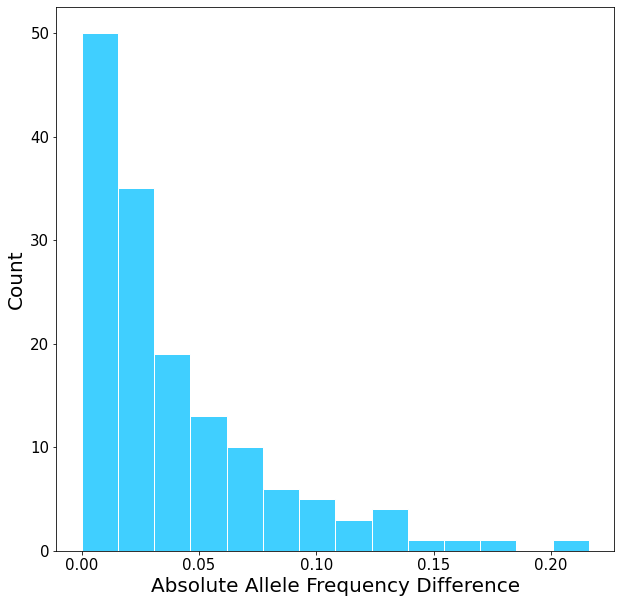

In [10]:
afd = pd.concat([L5_afd['AFD'], L7_afd['AFD'], L9_afd['AFD'], L10_afd['AFD']], axis = 0)
afd = abs(afd)

plt.figure(figsize = (10, 10))
sns.histplot(afd, color = 'deepskyblue', edgecolor='white')
plt.xlabel('Absolute Allele Frequency Difference', fontsize = 20)
plt.ylabel('Count', fontsize = 20)
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/Distribution_of_AFD.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

## Plotting putative QTLs

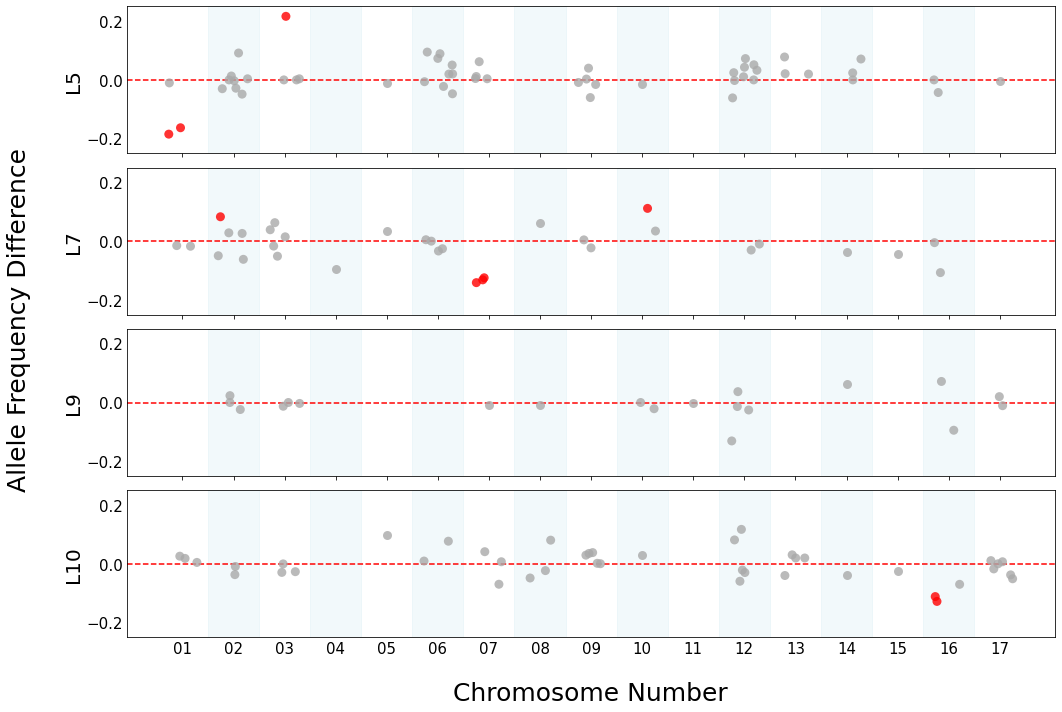

In [12]:
dfs = [L5_afd, L7_afd, L9_afd, L10_afd]
labels = ["L5", "L7", "L9", "L10"]

# 1. Define custom color mappings for EVERY subplot layer
# Format: "Label": {"Background": "color", "Significant": "color"}
color_themes = {
    "L5": {"Background": "darkgrey", "Significant": "red"},
    "L7": {"Background": "darkgrey", "Significant": "red"},  # Will also be hollow
    "L9": {"Background": "darkgrey", "Significant": "red"},
    "L10": {"Background": "darkgrey", "Significant": "red"},
}

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(15, 10))

for ax, df, label in zip(axes, dfs, labels):
    # 2. Enforce strict x-axis category sorting based on chrom_order
    df["chrom_no"] = pd.Categorical(
        df["chrom_no"], categories=chrom_order, ordered=True
    )

    # 3. Create a copy to safely inject a plotting classification status
    plot_df = df.copy()
    plot_df["QTL_Status"] = "Background"
    plot_df.loc[plot_df["fdr_bh_putative_QTL"] == "yes", "QTL_Status"] = (
        "Significant"
    )

    # 4. Extract your row-specific color theme and handle L7 hollow formatting
    palette_dict = color_themes[label]
    fc_style = "none" if label == "L7" else None

    # 5. Plot EVERYTHING together in ONE call to lock jitter coordinates perfectly
    sns.stripplot(
        data=plot_df,
        x="chrom_no",
        y="AFD",
        hue="QTL_Status",
        palette=palette_dict,
        hue_order=["Background", "Significant"],  # Ensures red paints on top
        alpha=0.8,
        size=9,
        jitter=0.3,  # Locks position calculation for background vs foreground
        legend=False,
        ax=ax,
        fc=fc_style,
    )

    # 6. Add baseline horizontal line
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1.5, label="Baseline")

    # 7. Set axis configurations and fonts
    ax.set_ylim(-0.25, 0.25)
    ax.set_ylabel(label, fontsize=20)
    ax.tick_params(axis="y", labelsize=15, size=0, width=3)

    # 8. Apply alternating background shaded boxes
    for i in range(len(chrom_order)):
        if i % 2 == 1:
            ax.axvspan(
                i - 0.5, i + 0.5, color="lightblue", alpha=0.15, zorder=0
            )

# Apply specific styling only to the bottom x-axis subplot (ax4)
axes[-1].tick_params(axis="x", labelsize=15, size=0, width=3)
axes[-1].set_xlabel("Chromosome Number", fontsize=25, labelpad=25)

# Add master vertical axis label centered across the figure window
fig.supylabel("Allele Frequency Difference", fontsize=25, y = 0.55)
plt.tight_layout(rect=[0.03, 0, 1, 1])
plt.show()
fig.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/Putative_QTLs.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

## Identifying Synonymous vs Nonsynonymous Candidate Genes 

In [54]:
mut_loc = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/Mutation_Location.txt', delimiter = '\t')
all_mutations = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/all_mutations.csv', delimiter = '\t')
v5 = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/v5_mutation_info.bed', delimiter = '\t', names = ['chromosome_v5', 'start_v5', 'end_v5', 'id'], index_col = 'id')
v6 = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/v6_mutation_info.bed', delimiter = '\t', names = ['chromosome', 'start', 'end', 'id'], index_col = 'id')
version6 = v6.join(v5)
all_mutations2 = pd.merge(version6, all_mutations, on=['chromosome', 'start', 'end'])

L5_put_genes = L5_afd.loc[L5_afd['fdr_bh_putative_QTL'] == 'yes']['loc'].values.tolist()
L5_v5_muts = all_mutations2.loc[all_mutations2['start'].isin(L5_put_genes)]['start_v5'].values.tolist()
L5_muts = mut_loc.loc[mut_loc['mutant_sample'] == 'CC2344_5']
display(L5_muts.loc[L5_muts['position'].isin(L5_v5_muts)])

L7_put_genes = L7_afd.loc[L7_afd['fdr_bh_putative_QTL'] == 'yes']['loc'].values.tolist()
L7_v5_muts = all_mutations2.loc[all_mutations2['start'].isin(L7_put_genes)]['start_v5'].values.tolist()
L7_muts = mut_loc.loc[mut_loc['mutant_sample'] == 'CC2344_7']
display(L7_muts.loc[L7_muts['position'].isin(L7_v5_muts)])

L10_put_genes = L10_afd.loc[L10_afd['fdr_bh_putative_QTL'] == 'yes']['loc'].values.tolist()
L10_v5_muts = all_mutations2.loc[all_mutations2['start'].isin(L10_put_genes)]['start_v5'].values.tolist()
L10_muts = mut_loc.loc[mut_loc['mutant_sample'] == 'CC2344_10']
display(L10_muts.loc[L10_muts['position'].isin(L10_v5_muts)])

,chromosome,position,ref,alt,qual,MQ,mutation,type,mutant_sample,call_method,HQ_calls,min_purity,het_count,number_mutants,number_genotypes,gc20,gc2000,pi1000,chromosome.1,position.1,reference_base,genic,exonic,intronic,intergenic,utr5,utr3,fold0,fold4,fold2,fold3,CDS,mRNA,rRNA,tRNA,feature_names,feature_types,feature_ID,cds_position,strand,frame,codon,aa,degen,FPKM,rho,FAIRE,recombination,Nonsyn_V_Syn,anc_codon,mut_codon,nonsense
183,chromosome_1,3123363,A,G,2195.810059,98.800003,A>G,SNP,CC2344_5,qual,15.0,1.0,0,1,2.0,0.523810,0.565717,0.027087,chromosome_1,3123363,A,1,1,0,0,0,0,0,0,1,0,1,1,0,0,"['Cre01.g019450', 'g455', '26903678', '26903679']","['gene', 'mRNA', 'CDS', 'exon']",26903679:26903678,95:95,+:+,2:2,aaa:aaa,K:K,2:2,1.04991474087,0.00096146,85.915,67425.0,synonymous,AAA,AAG,NaN
429,chromosome_1,6710963,G,A,388.980011,80.589996,G>A,SNP,CC2344_5,gq,15.0,1.0,0,1,2.0,0.809524,0.572714,0.035549,chromosome_1,6710963,G,0,0,0,1,0,0,0,0,0,0,0,0,0,0,[],[],.,.,.,.,.,.,.,.,0.00032529,139.05875,78440.0,NaN,NaN,NaN,NaN
1281,chromosome_3,3689019,T,C,1350.810059,94.389999,T>C,SNP,CC2344_5,gq,15.0,1.0,0,1,2.0,0.619048,0.645177,0.027723,chromosome_3,3689019,T,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['Cre03.g169250', '26901499']","['gene', 'mRNA', 'CDS', 'exon']",26901499,1143,-,0,acg,T,0,0.5589131364,0.00027212,.,86288.0,nonsynonymous,ACG,GCG,NaN


,chromosome,position,ref,alt,qual,MQ,mutation,type,mutant_sample,call_method,HQ_calls,min_purity,het_count,number_mutants,number_genotypes,gc20,gc2000,pi1000,chromosome.1,position.1,reference_base,genic,exonic,intronic,intergenic,utr5,utr3,fold0,fold4,fold2,fold3,CDS,mRNA,rRNA,tRNA,feature_names,feature_types,feature_ID,cds_position,strand,frame,codon,aa,degen,FPKM,rho,FAIRE,recombination,Nonsyn_V_Syn,anc_codon,mut_codon,nonsense
634,chromosome_2,1795759,C,T,758.809998,98.650002,C>T,SNP,CC2344_7,qual,15.0,1.000000,0,1,2.0,0.666667,0.605697,0.025669,chromosome_2,1795759,C,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['Cre02.g086850', '26900580']","['gene', 'mRNA', 'CDS', 'exon']",26900580,189,-,0,gca,A,0,7.07307141123,0.00091611,102.57,590517.0,nonsynonymous,GCA,ACA,NaN
2906,chromosome_7,3615070,G,A,1364.810059,98.639999,G>A,SNP,CC2344_7,qual,15.0,0.977273,0,1,2.0,0.714286,0.631184,0.032695,chromosome_7,3615070,G,1,1,0,0,0,0,0,1,0,0,1,1,0,0,"['Cre07.g336850', '26889986']","['gene', 'mRNA', 'CDS', 'exon']",26889986,236,+,2,acg,T,4,4.64666045735,0.046585,.,106277.0,synonymous,ACG,ACA,NaN
3015,chromosome_7,5558568,G,A,379.880005,98.779999,G>A,SNP,CC2344_7,qual,15.0,1.000000,0,1,2.0,0.761905,0.673663,0.032062,chromosome_7,5558568,G,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['Cre07.g351500', '26889452']","['gene', 'mRNA', 'exon', 'CDS']",26889452,3660,+,0,gcc,A,0,0.883331313633,0.0048286,.,116927.0,nonsynonymous,GCC,ACC,NaN
3018,chromosome_7,5608617,G,T,1195.810059,103.720001,G>T,SNP,CC2344_7,qual,15.0,0.975000,0,1,2.0,0.333333,0.573713,0.029127,chromosome_7,5608617,G,0,0,0,1,0,0,0,0,0,0,0,0,0,0,[],[],.,.,.,.,.,.,.,.,4.874e-05,.,109384.0,NaN,NaN,NaN,NaN
4007,chromosome_10,2314489,G,A,695.809998,96.639999,G>A,SNP,CC2344_7,qual,15.0,0.971429,0,1,2.0,0.619048,0.618191,0.023822,chromosome_10,2314489,G,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['g10721', '26905297']","['gene', 'mRNA', 'exon', 'CDS']",26905297,435,+,0,gag,E,0,0.0235950076,0.0014672,.,46672.0,nonsynonymous,GAG,AAG,NaN


,chromosome,position,ref,alt,qual,MQ,mutation,type,mutant_sample,call_method,HQ_calls,min_purity,het_count,number_mutants,number_genotypes,gc20,gc2000,pi1000,chromosome.1,position.1,reference_base,genic,exonic,intronic,intergenic,utr5,utr3,fold0,fold4,fold2,fold3,CDS,mRNA,rRNA,tRNA,feature_names,feature_types,feature_ID,cds_position,strand,frame,codon,aa,degen,FPKM,rho,FAIRE,recombination,Nonsyn_V_Syn,anc_codon,mut_codon,nonsense
6172,chromosome_16,6328575,C,T,754.809998,97.279999,C>T,SNP,CC2344_10,qual,15.0,0.95,0,1,2.0,0.904762,0.639180,0.021179,chromosome_16,6328575,C,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['Cre16.g674300', '26892510']","['gene', 'mRNA', 'CDS', 'exon']",26892510,489,-,0,gag,E,0,0.635479956233,0.012188,90.9005456349,75549.0,nonsynonymous,GAG,AAG,NaN
6273,chromosome_16,7764577,G,A,892.809998,98.720001,G>A,SNP,CC2344_10,qual,15.0,1.00,0,1,2.0,0.666667,0.644678,0.014046,chromosome_16,7764577,G,1,1,0,0,0,0,1,0,0,0,1,1,0,0,"['g16882', '26892306']","['gene', 'mRNA', 'CDS', 'exon']",26892306,1713,+,0,gac,D,0,4.45773212685,0.00022353,.,84167.0,nonsynonymous,GAC,AAC,NaN


## Identifying annotation of Candidate Genes 

In [30]:
Li_2019 = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/Li_2019.txt', delimiter = '\t')
Li_2019.loc[Li_2019['gene'] == 'Cre07.g336850']

,mutant_ID,side,chromosome,strand,min_position,gene,orientation,feature,gene_end_distances,intergenic_adjacent_genes,intergenic_orientations,intergenic_gene_distances,if_both_sides,confidence_level,if_fixed_position,LEAPseq_distance,LEAPseq_percent_confirming,flanking_seq,barcode,gene_name,defline,description,synonyms,PFAM,Panther,KOG,KEGG_ec,KEGG_Orthology,Gene_Ontology_terms,best_arabidopsis_TAIR10_hit_name,best_arabidopsis_TAIR10_hit_symbol,best_arabidopsis_TAIR10_hit_defline
42739,LMJ.RY0402.236709,3prime,chromosome_7,+,3615268,Cre07.g336850,sense,intron,"747,2349",-,-,-,-,3,no,398.0,100.000000,GCCTGCACTTACCGGCCCCTCACCTCCTGC,CAGCTCGTTGGAGCGCAGACAC,NaN,-,-,"g7838.t1,Cre07.g336850.t1.1",PF01661,PTHR11106,KOG2633,-,-,-,AT2G40600.1,-,appr-1-p processing enzyme family protein
42740,LMJ.RY0402.257055,5prime,chromosome_7,-,3617384,Cre07.g336850,antisense,3'UTR,"2863,233",-,-,-,-,3,no,802.0,100.000000,GAGTTTCCGAAGGGCATGCATGCCGGGGGC,GCACTCTAGCTTACGTGCGAAT,NaN,-,-,"g7838.t1,Cre07.g336850.t1.1",PF01661,PTHR11106,KOG2633,-,-,-,AT2G40600.1,-,appr-1-p processing enzyme family protein
140785,-,3prime,chromosome_7,-,3617004,Cre07.g336850,antisense,3'UTR,"2483,613",-,-,-,deletion,1,no,530.0,96.236990,ACACCCGGTGACACAGCACCTGGTGCACGC,GCCCCGGTTCACATGCTGAAGA,NaN,-,-,"g7838.t1,Cre07.g336850.t1.1",PF01661,PTHR11106,KOG2633,-,-,-,AT2G40600.1,-,appr-1-p processing enzyme family protein
140786,-,5prime,chromosome_7,-,3617012,Cre07.g336850,antisense,3'UTR,"2491,605",-,-,-,deletion,1,no,1049.0,99.560246,GCATGAAGGTGGGGTTGGGCACGAAGCTTA,TTTCTTTTGAAGCTATCCACTA,NaN,-,-,"g7838.t1,Cre07.g336850.t1.1",PF01661,PTHR11106,KOG2633,-,-,-,AT2G40600.1,-,appr-1-p processing enzyme family protein


## Identifying if Candidate Genes are Gene Duplicates

In [80]:
CREN_paralogs = pd.read_csv('/research/projects/chlamydomonas/NIexpression/data/gene_duplicates/paralogs/CREN_paralogousgenepairs.csv', delimiter = '\t')

candidate_genes = ['Cre01.g019450',
'Cre03.g169250',
'Cre02.g086850',
'Cre07.g336850',
'Cre07.g351500',
'Cre07.g351900',
'Cre07.g351950',
'Cre10.g434700',
'Cre10.g434726',
'Cre16.g674300',
'Cre16.g692228']

# CREN_paralogs.loc[CREN_paralogs['CREN_paralog'].isin(candidate_genes)]
Cren = pd.read_csv('/research/projects/chlamydomonas/NIexpression/data/gene_duplicates/paralogs/blasts/Cren_Cren.blastx.txt', delimiter = '\t', usecols = [0, 1, 2, 12], names = ['sample1', 'sample2', 'percent_id', 'query_cov'])
Cren['sample1'] = Cren['sample1'].str.replace('_4532.1', '')
Cren['sample2'] = Cren['sample2'].str.replace('_4532.1.p', '')
Cren.loc[(Cren['sample1'].isin(candidate_genes)) & (Cren['sample2'].isin(candidate_genes)) ]

<ipython-input-80-dfc2ba46df8f>:17: FutureWarning: The default value of regex will change from True to False in a future version.
  Cren['sample1'] = Cren['sample1'].str.replace('_4532.1', '')
<ipython-input-80-dfc2ba46df8f>:18: FutureWarning: The default value of regex will change from True to False in a future version.
  Cren['sample2'] = Cren['sample2'].str.replace('_4532.1.p', '')


,sample1,sample2,percent_id,query_cov
8444,Cre16.g674300,Cre16.g674300,100.0,43
9801,Cre16.g692228,Cre16.g692228,100.0,90
21208,Cre01.g019450,Cre01.g019450,100.0,36
30083,Cre03.g169250,Cre03.g169250,100.0,84
34042,Cre07.g336850,Cre07.g336850,100.0,38
34842,Cre07.g351500,Cre07.g351500,100.0,26
34864,Cre07.g351900,Cre07.g351900,100.0,85
34869,Cre07.g351950,Cre07.g351950,100.0,48
39930,Cre02.g086850,Cre02.g086850,100.0,32
43777,Cre10.g434700,Cre10.g434700,100.0,15


# Confirming mutations in VCF file

In [6]:
import pysam

mutation_loc = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/all_mutations.csv', delimiter = '\t')
chrom_convert = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/v5.3_to_v5.6_to_v6.csv', delimiter = '\t')
mutation_loc['new_v6_gene'] = 'intergenic'

for i in mutation_loc.index:
    old_v6 = mutation_loc.loc[i, 'gene']
    try:
        new_v6 = chrom_convert.loc[chrom_convert['v6'] == old_v6]['v5.5_gene'].item()
    except: continue
    mutation_loc.loc[i, 'new_v6_gene'] = new_v6
    
mutation_loc['sample'] = mutation_loc['sample'].str.replace('-', ' ').str.replace('CC', 'CC-')            
            
#### Number of mutations in candidate genes per sample ####
CC2344 = ["CC-2344 L1", "CC-2344 L2", "CC-2344 L3", "CC-2344 L4", "CC-2344 L5", "CC-2344 L6", "CC-2344 L7", "CC-2344 L8", "CC-2344 L9", "CC-2344 L10", "CC-2344 L11", "CC-2344 L12", "CC-2344 L13", "CC-2344 L14", "CC-2344 L15"]
CC2931 = ["CC-2931 L1", "CC-2931 L2", "CC-2931 L3", "CC-2931 L4", "CC-2931 L5", "CC-2931 L6", "CC-2931 L7", "CC-2931 L9", "CC-2931 L10", "CC-2931 L11", "CC-2931 L13", "CC-2931 L14", "CC-2931 L15"]

# vcf_path = "/research/projects/chlamydomonas/PhototacticRate/data/Prepared_Files/L9_ALL_RECOMBINANTS/L9_TOTAL.vcf.gz"
vcf_path = "/research/projects/chlamydomonas/PhototacticRate/data/Prepared_Files/WGS_MA/CC2344_L5.vcf.gz"
# Opens the tabix-indexed VCF file
vcf = pysam.TabixFile(vcf_path)

# Query a single position (Chromosome, Start, End)
# Note: pysam uses 0-based coordinates, so subtract 1 from VCF positions

CC2344 = ["CC-2344 L1", "CC-2344 L2", "CC-2344 L3", "CC-2344 L4", "CC-2344 L5", "CC-2344 L6", "CC-2344 L7", "CC-2344 L8", "CC-2344 L9", "CC-2344 L10", "CC-2344 L11", "CC-2344 L12", "CC-2344 L13", "CC-2344 L14", "CC-2344 L15"]
CC2931 = ["CC-2931 L1", "CC-2931 L2", "CC-2931 L3", "CC-2931 L4", "CC-2931 L5", "CC-2931 L6", "CC-2931 L7", "CC-2931 L9", "CC-2931 L10", "CC-2931 L11", "CC-2931 L13", "CC-2931 L14", "CC-2931 L15"]
samples = CC2344 + CC2931
# samples = ['CC-2344 L5']
for samp in samples:
    tab = 0
    index = []
    mut = mutation_loc.loc[mutation_loc['sample'] == samp]
    for i in mut.index:
        
        chromosome = mut.loc[i, 'chromosome']
        position = mut.loc[i, 'start']
        
        try:
            for row in vcf.fetch(chromosome, position - 1, position):
                tab += 1
                index.append(i)
#                 print(row)
#             else:
#                 if row not in vcf.fetch(chromosome, position - 1, position):
#                     print(row)  # Prints the full VCF line
        except ValueError:
            print(f"Region {chromosome}:{position} not found.")
    display(samp + '= ' + str(tab))
    display(len(mut))

Region contig_28:27991 not found.
Region MT_plus_R:168490 not found.


'CC-2344 L1= 19'

398

Region contig_49:327 not found.


'CC-2344 L2= 3'

...

97

'CC-2931 L14= 2'

79

'CC-2931 L15= 11'

141

# GO-annotated Candidate Gene Set

## Identifying variants in candidate genes

In [6]:
mutation_loc = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/all_mutations.csv', delimiter = '\t')
chrom_convert = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/v5.3_to_v5.6_to_v6.csv', delimiter = '\t')
mutation_loc['new_v6_gene'] = 'intergenic'

for i in mutation_loc.index:
    old_v6 = mutation_loc.loc[i, 'gene']
    try:
        new_v6 = chrom_convert.loc[chrom_convert['v6'] == old_v6]['v5.5_gene'].item()
    except: continue
    mutation_loc.loc[i, 'new_v6_gene'] = new_v6
    
mutation_loc['sample'] = mutation_loc['sample'].str.replace('-', ' ').str.replace('CC', 'CC-')            
            
#### Number of mutations in candidate genes per sample ####
CC2344 = ["CC-2344 L1", "CC-2344 L2", "CC-2344 L3", "CC-2344 L4", "CC-2344 L5", "CC-2344 L6", "CC-2344 L7", "CC-2344 L8", "CC-2344 L9", "CC-2344 L10", "CC-2344 L11", "CC-2344 L12", "CC-2344 L13", "CC-2344 L14", "CC-2344 L15"]
CC2931 = ["CC-2931 L1", "CC-2931 L2", "CC-2931 L3", "CC-2931 L4", "CC-2931 L5", "CC-2931 L6", "CC-2931 L7", "CC-2931 L9", "CC-2931 L10", "CC-2931 L11", "CC-2931 L13", "CC-2931 L14", "CC-2931 L15"]

mut_candidate = []

for sample in CC2344 + CC2931:
    subset = mutation_loc.loc[mutation_loc['sample'] == sample]
    genes = subset.loc[subset['new_v6_gene'].isin(allcandidate_genes)]
    mutation_loc.loc[subset.index, 'no_candidate_genes'] = len(genes)
    mut_candidate += list(genes['new_v6_gene'])
    
#### Number of strains per mutated candidate genes ####
mutated_candidate = pd.DataFrame(index = mut_candidate)
for idx in mutated_candidate.index:
    a = []
#     for sample in CC2344 + CC2931:
    for sample in ['CC-2344 L10', 'CC-2344 L13', 'CC-2344 L1', 'CC-2344 L8', 'CC-2931 L2', 'CC-2931 L13', 'CC2931 L3', 'CC2931 L4']:
        subset = mutation_loc.loc[mutation_loc['sample'] == sample]
        if len(subset.loc[subset['new_v6_gene'] == idx]) != 0:
            a.append(sample)
    mutated_candidate.loc[idx, 'strains'] = str(a)
    mutated_candidate.loc[idx, 'no_hits'] = len(a)
mutated_candidate

,strains,no_hits
Cre05.g244250,['CC-2344 L1'],1.0
Cre10.g430700,['CC-2344 L1'],1.0
Cre09.g393450,['CC-2344 L1'],1.0
Cre11.g475600,['CC-2344 L1'],1.0
Cre11.g475000,['CC-2344 L1'],1.0
...,...,...
Cre06.g268800,[],0.0
Cre13.g585150,[],0.0
Cre01.g025400,[],0.0
Cre01.g050850,[],0.0


In [37]:
names = ['chrom', 'extra1', 'type', 'start', 'end', 'extra2', 'extra3', 'extra4', 'extra5']
anno = pd.read_csv('/research/references/chlamydomonas/6.1_chlamy/annotation/CreinhardtiiCC_4532_707_v6.1.gene.gff3', delimiter = '\t', skiprows = 6, names = names)

extreme_pheno = mutated_candidate.loc[mutated_candidate['no_hits'] != 0].reset_index()
extreme_pheno = extreme_pheno.drop_duplicates(subset = ['index', 'strains'])
new_names = {"['CC-2344 L1']": 'CC-2344 L1', "['CC-2344 L10']": 'CC-2344 L10', "['CC-2344 L13']": 'CC-2344 L13', "['CC-2344 L8']": 'CC-2344 L8',
            "['CC-2931 L2']": 'CC-2931 L2', "['CC-2931 L13']": 'CC-2931 L13', "['CC-2931 L3']": 'CC-2931 L3', "['CC-2931 L4']": 'CC-2931 L4'}
extreme_pheno['strains'] = extreme_pheno['strains'].replace(new_names)
extreme_pheno.drop_duplicates(subset=['index', 'strains'])

new_row = {'index': 'Cre10.g429750', 'strains': 'CC-2344 L10', 'no_hits': 1}
new_row2 = {'index': 'Cre10.g429750', 'strains': 'CC-2931 L2', 'no_hits': 1}

df_new_row = pd.DataFrame([new_row, new_row2])
extreme_pheno = pd.concat([extreme_pheno, df_new_row], ignore_index=True).drop(22)
extreme_pheno = extreme_pheno.loc[extreme_pheno['strains'] == 'CC-2344 L1'] ###focusing on a subset of strains

for i in extreme_pheno.index:
    sample = extreme_pheno.loc[i, 'strains'] 
    gene = extreme_pheno.loc[i, 'index']
    mut = mutation_loc.loc[(mutation_loc['sample'] == sample) & (mutation_loc['new_v6_gene'] == gene)]
    chrom = mut.loc[mut.index[0], 'chromosome']
    start = mut.loc[mut.index[0], 'start']
    end = mut.loc[mut.index[0], 'end']
    display(sample)
    display(anno.loc[(anno['chrom'] == chrom) & (anno['start'] <= start) & (anno['end'] >= end)])

'CC-2344 L1'

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5
118832,chromosome_05,phytozomev13,gene,509432,532412,.,+,.,ID=Cre05.g244250_4532.v6.1;Name=Cre05.g244250_...
118833,chromosome_05,phytozomev13,mRNA,509432,532412,.,+,.,ID=Cre05.g244250_4532.1.v6.1;Name=Cre05.g24425...
118884,chromosome_05,phytozomev13,three_prime_UTR,531405,532412,.,+,.,ID=Cre05.g244250_4532.1.v6.1.three_prime_UTR.3...


'CC-2344 L1'

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5
222717,chromosome_10,phytozomev13,gene,1781793,1806186,.,+,.,ID=Cre10.g430700_4532.v6.1;Name=Cre10.g430700_...
222718,chromosome_10,phytozomev13,mRNA,1781793,1806186,.,+,.,ID=Cre10.g430700_4532.1.v6.1;Name=Cre10.g43070...
222745,chromosome_10,phytozomev13,CDS,1797201,1797312,.,+,0,ID=Cre10.g430700_4532.1.v6.1.CDS.27;Parent=Cre...


'CC-2344 L1'

...

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5
377189,chromosome_17,phytozomev13,gene,3478693,3483672,.,-,.,ID=Cre17.g723950_4532.v6.1;Name=Cre17.g723950_...
377190,chromosome_17,phytozomev13,mRNA,3478693,3483672,.,-,.,ID=Cre17.g723950_4532.1.v6.1;Name=Cre17.g72395...
377205,chromosome_17,phytozomev13,three_prime_UTR,3478693,3479499,.,-,.,ID=Cre17.g723950_4532.1.v6.1.three_prime_UTR.1...
377207,chromosome_17,phytozomev13,mRNA,3478958,3483464,.,-,.,ID=Cre17.g723950_4532.2.v6.1;Name=Cre17.g72395...
377223,chromosome_17,phytozomev13,three_prime_UTR,3478958,3479499,.,-,.,ID=Cre17.g723950_4532.2.v6.1.three_prime_UTR.1...


'CC-2344 L1'

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5
319281,chromosome_14,phytozomev13,gene,2558189,2582867,.,-,.,ID=Cre14.g624950_4532.v6.1;Name=Cre14.g624950_...
319282,chromosome_14,phytozomev13,mRNA,2558189,2582867,.,-,.,ID=Cre14.g624950_4532.2.v6.1;Name=Cre14.g62495...
319313,chromosome_14,phytozomev13,CDS,2570805,2570933,.,-,0,ID=Cre14.g624950_4532.2.v6.1.CDS.30;Parent=Cre...
319361,chromosome_14,phytozomev13,mRNA,2558189,2582867,.,-,.,ID=Cre14.g624950_4532.3.v6.1;Name=Cre14.g62495...
319392,chromosome_14,phytozomev13,CDS,2570805,2570933,.,-,0,ID=Cre14.g624950_4532.3.v6.1.CDS.30;Parent=Cre...
319417,chromosome_14,phytozomev13,mRNA,2558336,2582867,.,-,.,ID=Cre14.g624950_4532.4.v6.1;Name=Cre14.g62495...
319448,chromosome_14,phytozomev13,CDS,2570805,2570933,.,-,0,ID=Cre14.g624950_4532.4.v6.1.CDS.30;Parent=Cre...
319474,chromosome_14,phytozomev13,mRNA,2558336,2582867,.,-,.,ID=Cre14.g624950_4532.5.v6.1;Name=Cre14.g62495...
319505,chromosome_14,phytozomev13,CDS,2570805,2570933,.,-,0,ID=Cre14.g624950_4532.5.v6.1.CDS.30;Parent=Cre...
319531,chromosome_14,phytozomev13,mRNA,2558336,2582867,.,-,.,ID=Cre14.g624950_4532.6.v6.1;Name=Cre14.g62495...


'CC-2344 L1'

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5
319071,chromosome_14,phytozomev13,gene,2500894,2507505,.,+,.,ID=Cre14.g624400_4532.v6.1;Name=Cre14.g624400_...
319072,chromosome_14,phytozomev13,mRNA,2500894,2507505,.,+,.,ID=Cre14.g624400_4532.1.v6.1;Name=Cre14.g62440...


## Identifying Candidate DEGs

In [7]:
max_distance = pd.read_csv('/research/projects/chlamydomonas/PhototacticRate/data/average_maximum_distance3.csv', delimiter = '\t')
CC2344_ANC = max_distance[max_distance['strain'] == 'CC-2344 ANC']['mean'].iloc[0]
CC2931_ANC = max_distance[max_distance['strain'] == 'CC-2931 ANC']['mean'].iloc[0]

data = mutation_loc[['sample', 'no_candidate_genes']].drop_duplicates(keep = 'first').dropna()
data.columns = ['strain', 'no_candidate_genes']

#### Number of mutations per strain ####
for i in mutation_loc['sample'].unique():
    data.loc[data[data['strain'] == i].index, 'mutations'] = len(mutation_loc[mutation_loc['sample'] == i])

#### Calculating relative average maximum distance ####
data = pd.merge(data, max_distance, on = ['strain'])
section = data[data['strain'].isin(CC2344)]['mean']
data.loc[section.index, 'mean'] = section/CC2344_ANC
section = data[data['strain'].isin(CC2931)]['mean']
data.loc[section.index, 'mean'] = section/CC2931_ANC
data['absolute_divergence'] = data['mean']
data.loc[data.loc[data['mean'] < 1].index, 'absolute_divergence'] = data.loc[data.loc[data['mean'] < 1].index, 'absolute_divergence']**(-1)

#### DEGs in candidate genes ####
degs = pd.read_csv('/research/projects/chlamydomonas/MAexpression/analysis/DEGs/total_genes_v6_1.csv', sep = ',')
candidate_degs = {}
no_candidate_degs = {}
for strain in degs.columns:
    candidate_degs[strain] = list(set(degs[strain]).intersection(allcandidate_genes))
    no_candidate_degs[strain] = len(list(set(degs[strain]).intersection(allcandidate_genes)))
candidate_degs1 = pd.DataFrame(dict([(key, pd.Series(value)) for key, value in candidate_degs.items()]))
no_candidate_degs = pd.DataFrame(data = no_candidate_degs.values(), index = no_candidate_degs.keys(), columns = ['no_degs']).reset_index()
no_candidate_degs.columns = ['strain', 'no_degs']
no_candidate_degs['strain'] = no_candidate_degs['strain'].str.replace('-', ' ').str.replace('CC', 'CC-')
data = pd.merge(no_candidate_degs, data, on = ['strain'])

dic_fitness = {}
fitness = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/Mutation_Fitness.txt', delimiter = '\t')
fitness['Sample'] = fitness['Sample'].str.replace('_', ' L').str.replace('CC', 'CC-')
fitness = fitness.loc[fitness['Sample'].isin(CC2344 + CC2931)]

for i in fitness.index.values:
    dic_fitness[fitness.at[i,'Sample']] = fitness.at[i, 'Average_realtive']

#### Recording fitness per sample ####
fitness = pd.Series(dic_fitness)
fitness['CC2344-ANC'] = 0
fitness['CC2931-ANC'] = 0
fitness = pd.DataFrame(fitness, columns = ['fitness']).reset_index()
fitness.columns = ['strain', 'fitness']
data = pd.merge(data, fitness)
data

<ipython-input-7-e1846877c778>:28: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  candidate_degs1 = pd.DataFrame(dict([(key, pd.Series(value)) for key, value in candidate_degs.items()]))


,strain,no_degs,no_candidate_genes,mutations,MotA1,MotA2,MotA3,MotA4,MotA5,mean,std,n_MotA,n_raw_rows,type,absolute_divergence,fitness
0,CC-2931 L1,41,3.0,89.0,12.666667,11.000000,9.666667,14.000000,12.666667,1.343284,1.505545,5,10,CC-2931,1.343284,-0.02
1,CC-2931 L2,7,6.0,124.0,16.000000,17.333333,12.666667,12.000000,16.000000,1.656716,2.082733,5,5,CC-2931,1.656716,-0.04
2,CC-2931 L5,28,16.0,339.0,10.000000,15.333333,10.666667,11.333333,10.666667,1.298507,1.913693,5,5,CC-2931,1.298507,-0.06
3,CC-2344 L1,88,21.0,398.0,8.000000,9.333333,5.333333,8.000000,8.666667,0.485197,1.359739,5,5,CC-2344,2.061017,-0.04
4,CC-2344 L10,25,2.0,59.0,18.666667,18.000000,18.666667,17.333333,16.000000,1.093750,0.997775,5,5,CC-2344,1.093750,-0.00
5,CC-2344 L11,123,3.0,45.0,10.000000,8.666667,10.666667,9.666667,6.666667,0.563322,1.392041,5,10,CC-2344,1.775182,-0.01
6,CC-2344 L12,75,3.0,74.0,9.333333,13.333333,11.333333,6.666667,14.666667,0.682566,2.847221,5,5,CC-2344,1.465060,-0.02
7,CC-2344 L13,1,1.0,49.0,20.000000,19.333333,20.000000,18.000000,20.000000,1.200658,0.777460,5,5,CC-2344,1.200658,-0.00
8,CC-2344 L2,7,2.0,81.0,9.333333,6.666667,8.000000,10.000000,11.333333,0.559211,1.611073,5,5,CC-2344,1.788235,0.00
9,CC-2344 L3,1,7.0,63.0,10.666667,10.000000,7.333333,15.333333,9.333333,0.649671,2.646591,5,5,CC-2344,1.539241,-0.02


# Plots

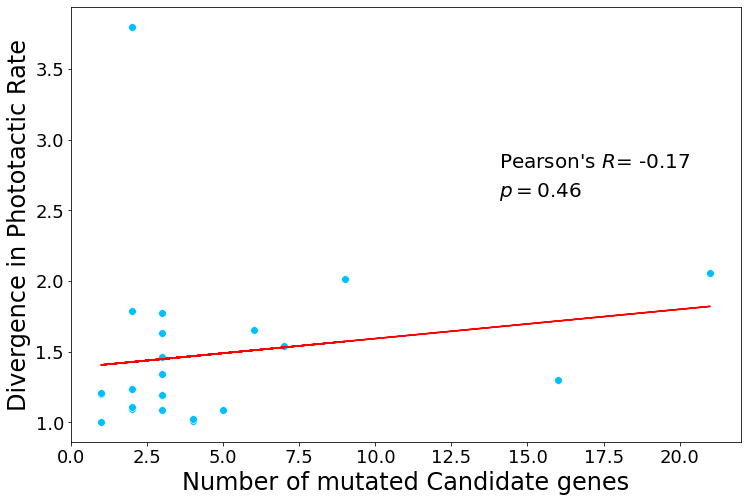

In [8]:
plt.figure(figsize = (12,8))
sns.scatterplot(data = data, x = 'no_candidate_genes', y = 'absolute_divergence', s = 60, color = 'deepskyblue')

plt.xticks(fontsize = 18)
plt.yticks(fontsize = 18)
plt.xlabel('Number of mutated Candidate genes', fontsize = 24)
plt.ylabel('Divergence in Phototactic Rate', fontsize = 24)

R, pval = pearsonr(data['no_candidate_genes'], data['absolute_divergence'])
Round = lambda x, n: eval('"%.'+str(int(n))+'f" % '+repr(int(x)+round(float('.'+str(float(x)).split('.')[1]),n)))

plt.figtext(0.62, 0.60, "Pearson's $R$= -" + Round(R, 2), fontsize=20)
plt.figtext(0.62, 0.55, '$p=$' + Round(pval, 2), fontsize=20)

z = np.polyfit(data['no_candidate_genes'], data['absolute_divergence'], 1)
p = np.poly1d(z)
plt.plot(data['no_candidate_genes'], p(data['no_candidate_genes']), 'r')
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/divergence_vs_candidategenes.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

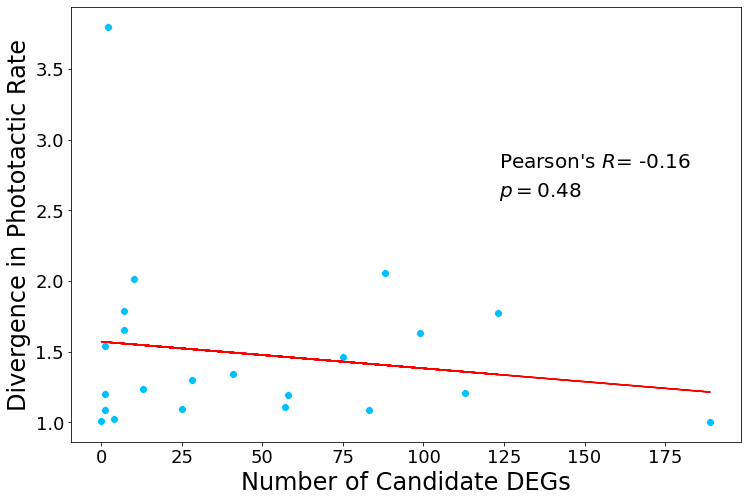

In [9]:
plt.figure(figsize = (12,8))
sns.scatterplot(data = data, x = 'no_degs', y = 'absolute_divergence', s = 60, color = 'deepskyblue')

plt.xticks(fontsize = 18)
plt.yticks(fontsize = 18)
plt.xlabel('Number of Candidate DEGs', fontsize = 24)
plt.ylabel('Divergence in Phototactic Rate', fontsize = 24)

R, pval = pearsonr(data['no_degs'], data['absolute_divergence'])
Round = lambda x, n: eval('"%.'+str(int(n))+'f" % '+repr(int(x)+round(float('.'+str(float(x)).split('.')[1]),n)))

plt.figtext(0.62, 0.60, "Pearson's $R$= -" + Round(R, 2), fontsize=20)
plt.figtext(0.62, 0.55, '$p=$' + Round(pval, 2), fontsize=20)

z = np.polyfit(data['no_degs'], data['absolute_divergence'], 1)
p = np.poly1d(z)
plt.plot(data['no_degs'], p(data['no_degs']), 'r')
plt.savefig('/research/projects/chlamydomonas/PhototacticRate/data/Figures/divergence_vs_candidateDEGs.pdf', dpi = 1600, bbox_inches = 'tight', format = 'pdf')

# Structural Mutations

In [36]:
def genes_overlapping_SM(df):
    """ This code identifies the name of genes overlapped by structural mutations. """
    
    names = ['chrom', 'extra1', 'type', 'start', 'end', 'extra2', 'strand', 'extra4', 'extra5']
    annotation = pd.read_csv('/research/references/chlamydomonas/6.1_chlamy/annotation/CreinhardtiiCC_4532_707_v6.1.gene.gff3', delimiter = '\t', skiprows = 6, names = names)
    annotation['genename'] = annotation.loc[annotation['type'] == 'gene']['extra5'].str.split('Name=', expand = True)[1].str.split('_4532', expand = True)[0]
    annotation = annotation.loc[annotation['type'] == 'gene']
    
    df['genename'] = 'intergenic'
    df = df.drop(columns = ['index'])

    #### Extracting genenames of overlapping or within structural mutations ####
    for idx in df.index.values:
        chrom = annotation.loc[(annotation['chrom'] == df.at[idx, 'chrom']) & (annotation['strand'] == df.at[idx, 'strand'])]
        end_SM_in_gene = chrom.loc[(chrom['start'] <= df.at[idx, 'chromEnd']) & (chrom['end'] >= df.at[idx, 'chromEnd'])] ## finding the genes at the end of the SM
        start_SM_in_gene = chrom.loc[(chrom['start'] <= df.at[idx, 'chromStart']) & (chrom['end'] >= df.at[idx, 'chromStart'])]
        SM_within_gene = chrom.loc[(chrom['start'] <= df.at[idx, 'chromStart']) & (chrom['end'] >= df.at[idx, 'chromEnd'])]
        genes_in_SM = chrom.loc[(df.at[idx, 'chromStart'] <= chrom['start']) & (chrom['end'] <= df.at[idx, 'chromEnd'])]
        chrom = pd.concat([end_SM_in_gene, start_SM_in_gene, SM_within_gene, genes_in_SM], axis = 0).drop_duplicates()
        if len(chrom) != 0:
            df.at[idx, 'genename'] = list(np.unique(chrom['genename'])) ## Adding the name of the gene(s) that the structural mutation overlap with
    return df

In [40]:
## Opening files with structural mutations categorized by the mutation type ##
df_inv = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_inversions.csv', delimiter = '\t')
df_del = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_deletions.csv', delimiter = '\t')
df_dup = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_duplications.csv', delimiter = '\t')
df_trans = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_translocations.csv', delimiter = '\t')
df_ex = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_excisions.csv', delimiter = '\t')
df_ins = pd.read_csv('/research/projects/chlamydomonas/MAexpression/genome_info/mutation_info/structural_mutations/cleaned_by_distance_insertions.csv', delimiter = '\t')

## Combining structural mutations into a single dataframe ##
SM = pd.concat([df_del, df_dup, df_ex, df_ins, df_inv, df_trans], axis = 0).drop(columns = ['Unnamed: 0']).reset_index()
SM['sample'] = SM['sample'].replace('L', 'CC2931-L', regex = True)
SM = genes_overlapping_SM(SM)
SM = SM.explode('genename')

In [42]:
set(SM.loc[SM['genename'] != 'intergenic']['genename']).intersection(allcandidate_genes)

{'Cre01.g019900',
 'Cre02.g141950',
 'Cre05.g240700',
 'Cre07.g321400',
 'Cre18.g749947'}

In [49]:
filtered_anno.loc[filtered_anno['transcriptName'].isin(['Cre01.g019900','Cre02.g141950','Cre05.g240700','Cre07.g321400','Cre18.g749947'])]

,transcriptName,Best-hit-clamy-defline,annofile_GO,annofile_match_source
799,Cre01.g019900,Flagellar Associated Protein 384,NaN,flagella
9510,Cre05.g240700,Flagellar Associated Protein 378,GO:0005044 GO:0008237 GO:0016020,flagella
32280,Cre18.g749947,Coiled-Coil Flagellar Associated Protein 21,NaN,flagella


In [63]:
anno_cg = annotation.loc[annotation['genename'].isin(allcandidate_genes)]
flank = 100 ## bps

for i in SM.index:
    chrom = SM.loc[i, 'chrom']
    start = SM.loc[i, 'chromStart']
    end = SM.loc[i, 'chromEnd']
    
    try:
        section = anno_cg.loc[anno_cg['chrom'] == chrom]
        nearby_gene = section.loc[(abs(section['end'] - start) <= flank) | (abs(section['start'] - end) <= flank)]['genename'].values[0]
        SM.loc[i, 'nearby_genes'] = nearby_gene
    except: continue
SM

,Unnamed: 0.1,chrom,chromStart,chromEnd,extra1,strand,sample,type,old_chrom,old_chromStart,old_chromEnd,direction,transposable_elements,genename,nearby_genes
0,0,chromosome_12,1952396,1952524,0,+,CC2931-L14,deletion,chromosome_12,1884089,1884221.0,NaN,NaN,Cre12.g511400,NaN
1,1,chromosome_05,281797,291722,0,+,CC2931-L15,deletion,chromosome_05,267197,299321.0,NaN,NaN,intergenic,NaN
2,2,chromosome_01,6915222,6920275,0,+,CC2931-L15,deletion,chromosome_10,7918878,7923936.0,NaN,NaN,intergenic,NaN
3,3,chromosome_01,4768923,4780161,0,+,CC2931-L1,deletion,chromosome_10,5819107,5830084.0,NaN,NaN,Cre01.g033150,NaN
4,4,chromosome_15,208023,224209,0,+,CC2931-L15,deletion,chromosome_15,78407,93154.0,NaN,NaN,Cre15.g801679,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,24,chromosome_03,6784242,6784251,0,+,CC2931-L15,translocation,chromosome_03,6564255,NaN,NaN,NaN,intergenic,NaN
244,25,chromosome_04,1957232,1957242,0,+,CC2931-L15,translocation,chromosome_04,1788682,NaN,NaN,NaN,intergenic,NaN
245,26,chromosome_04,645523,645533,0,+,CC2931-L2,translocation,chromosome_04,584948,NaN,NaN,NaN,intergenic,NaN
246,27,chromosome_13,4758005,4758015,0,+,CC2931-L15,translocation,chromosome_13,4700919,NaN,NaN,NaN,intergenic,NaN


In [64]:
SM['nearby_genes'].dropna()

30     Cre02.g141950
144    Cre06.g278194
173    Cre01.g030200
211    Cre06.g278194
Name: nearby_genes, dtype: object

In [65]:
filtered_anno.loc[filtered_anno['transcriptName'].isin(['Cre02.g141950','Cre06.g278194','Cre01.g030200','Cre06.g278194'])]

,transcriptName,Best-hit-clamy-defline,annofile_GO,annofile_match_source
1183,Cre01.g030200,Flagellar Associated Protein 6,GO:0003824 GO:0004722 GO:0006470,flagella
11104,Cre06.g278194,Flagellar Associated Protein 236,NaN,flagella


In [61]:
SM.loc[211]

Unnamed: 0.1                         6
chrom                    chromosome_06
chromStart                     3922466
chromEnd                       3922471
extra1                               0
strand                               +
sample                      CC2931-L14
type                         inversion
old_chrom                chromosome_06
old_chromStart                 6011313
old_chromEnd                 6244343.0
direction                         left
transposable_elements              NaN
genename                    intergenic
nearby_genes             Cre06.g278194
Name: 211, dtype: object

In [62]:
anno_cg.loc[anno_cg['genename'] == 'Cre06.g278194']

,chrom,extra1,type,start,end,extra2,extra3,extra4,extra5,genename
137112,chromosome_06,phytozomev13,gene,3922398,3927363,.,-,.,ID=Cre06.g278194_4532.v6.1;Name=Cre06.g278194_...,Cre06.g278194
